# Assignment 3 — Module 3: Evolutionary and Swarm Optimization

**Student Name:** Arendra Singh Rajput  
**Roll No.:** 2023BTCSE003  
**Enrollment No.:** JLU08391  
**Course:** B.Tech CSE, 4th Year  
**Subject:** Soft Computing Exercise  

---

## Practical 8: Particle Swarm Optimization

### Aim
To implement a simple Particle Swarm Optimization (PSO) algorithm for solving an optimization problem using Python.

### Theory
**Particle Swarm Optimization** moves a swarm of particles through the search space. Each particle has a position $\mathbf{x}_i$ and velocity $\mathbf{v}_i$, updated as

$$\mathbf{v}_i \leftarrow w\,\mathbf{v}_i + c_1 r_1 (\mathbf{p}_i - \mathbf{x}_i) + c_2 r_2 (\mathbf{g} - \mathbf{x}_i), \qquad \mathbf{x}_i \leftarrow \mathbf{x}_i + \mathbf{v}_i$$

where $\mathbf{p}_i$ is the particle's personal best, $\mathbf{g}$ the global best, $w$ the inertia weight and $c_1, c_2$ the acceleration coefficients. We use the multimodal **Rastrigin function** as the test problem:

$$f(\mathbf{x}) = 10n + \sum_{i=1}^{n}\left[x_i^2 - 10\cos(2\pi x_i)\right], \qquad \text{global minimum } f(\mathbf{0})=0$$

### Rastrigin objective and PSO implementation

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def rastrigin(x):
    return 10*len(x) + np.sum(x**2 - 10*np.cos(2*np.pi*x))

def pso(func, dim=5, n_particles=30, iters=200, low=-5.12, high=5.12,
        w=0.729, c1=1.49, c2=1.49, seed=0):
    gen_rng = np.random.default_rng(seed)
    x = gen_rng.uniform(low, high, (n_particles, dim))
    v = gen_rng.uniform(-1, 1, (n_particles, dim)) * 0.1
    pbest = x.copy()
    pbest_val = np.array([func(p) for p in x])
    g_idx = np.argmin(pbest_val)
    gbest, gbest_val = pbest[g_idx].copy(), pbest_val[g_idx]
    history = []

    for _ in range(iters):
        r1 = gen_rng.random((n_particles, dim))
        r2 = gen_rng.random((n_particles, dim))
        v = w*v + c1*r1*(pbest - x) + c2*r2*(gbest - x)
        v = np.clip(v, -1, 1)                   # velocity clamping
        x = np.clip(x + v, low, high)

        vals = np.array([func(p) for p in x])
        improved = vals < pbest_val
        pbest[improved] = x[improved]
        pbest_val[improved] = vals[improved]
        if pbest_val.min() < gbest_val:
            g_idx = np.argmin(pbest_val)
            gbest, gbest_val = pbest[g_idx].copy(), pbest_val[g_idx]
        history.append(gbest_val)
    return gbest, gbest_val, history

best_x, best_val, hist = pso(rastrigin)
print("Best position :", np.round(best_x, 4))
print("Best f(x)     :", f"{best_val:.6f}")

Best position : [-0.    -0.995 -0.995 -0.    -0.995]
Best f(x)     : 2.984877


### Convergence plot

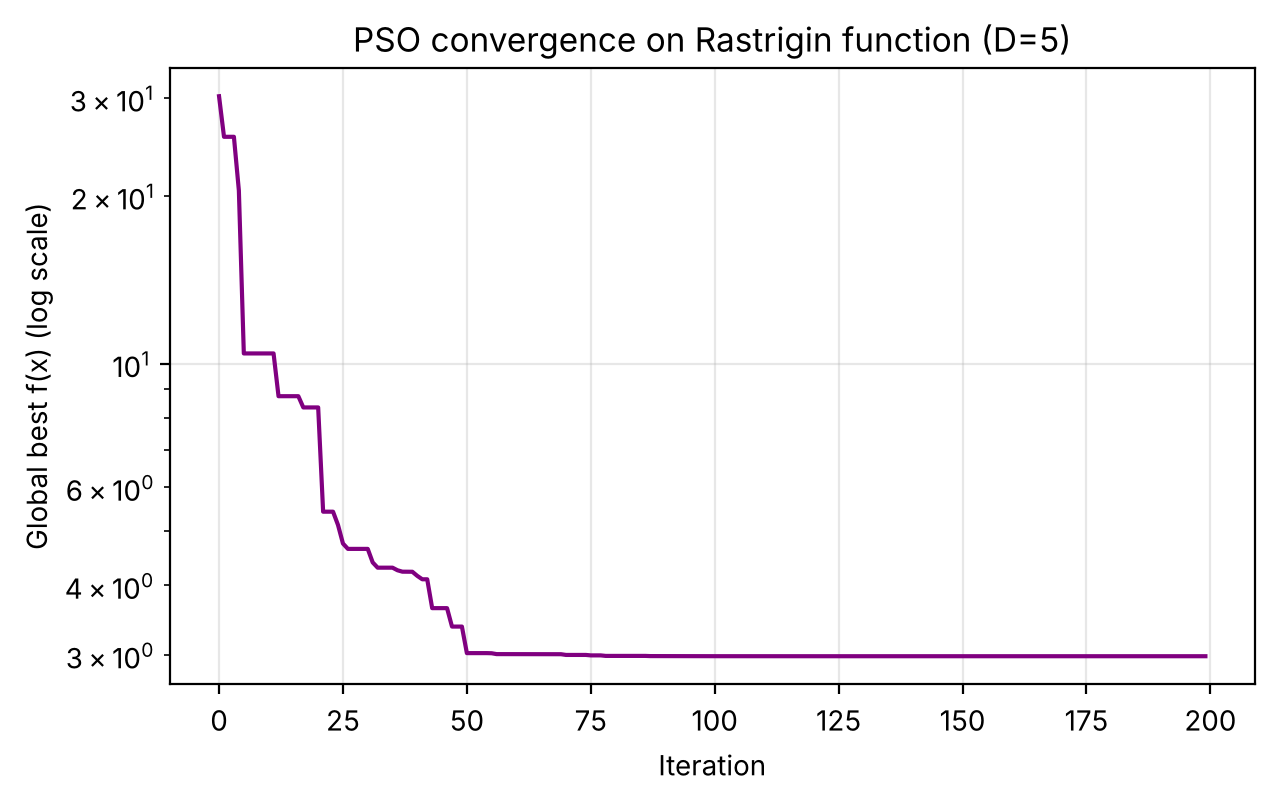

In [2]:
plt.figure(figsize=(7, 4))
plt.plot(hist, color='purple')
plt.yscale('log')
plt.xlabel('Iteration'); plt.ylabel('Global best f(x) (log scale)')
plt.title('PSO convergence on Rastrigin function (D=5)')
plt.grid(True, alpha=0.3); plt.show()

### Effect of swarm size

In [3]:
for n in [10, 30, 60]:
    results = [pso(rastrigin, n_particles=n, seed=s)[1] for s in range(10)]
    print(f"Swarm size {n:3d}: mean best f(x) over 10 runs = {np.mean(results):.4f}")

Swarm size  10: mean best f(x) over 10 runs = 5.9697


Swarm size  30: mean best f(x) over 10 runs = 2.4876


Swarm size  60: mean best f(x) over 10 runs = 2.3887


### Observation
- The global best value falls quickly in the early iterations as particles are pulled toward good regions, then improves more slowly.
- Because Rastrigin has many local minima, individual runs may stall in a local minimum. Averaging over seeds shows the typical quality.
- Increasing the swarm from 10 to 30 particles improves the average result considerably, but going from 30 to 60 gives only a small further gain while costing twice the evaluations.

### Conclusion
Implemented PSO with inertia, cognitive and social terms, applied it to the multimodal Rastrigin function, and studied the effect of swarm size.